# Análisis y comparación de corridas de la red de localización

Compara corridas de `localizacion/train.py` a partir de lo que ya está en disco: el `log.csv` de cada corrida y sus evaluaciones de `localizacion/evaluate.py` sobre los conjuntos pregenerados `test_snr` y `test_snr_mezcla` (`resumen.yaml`, `gt_eval.csv`, `predicciones.csv`). Los ejemplos leen además las imágenes de `localizacion/datos/test_snr_mezcla/`. **No corre la red.**

- Las corridas se eligen en la celda **Configuración**; es la única que hay que editar para agregar o quitar corridas.
- Si a una corrida le falta una evaluación, el notebook lo avisa con el comando de `evaluate.py` que hay que correr y la omite en las gráficas de ese conjunto.
- Cada gráfica tiene un parámetro `GUARDAR` (falso por defecto) que la exporta a `figuras/notebook/` en PNG (300 dpi) y PDF.
- Las funciones compartidas con `figuras/figuras_localizacion.py` (paleta, distancia al brillante, intervalos de Wilson, dibujo de frames) están en `figuras/comun_localizacion.py`.

Kernel: el entorno conda `tesis` (necesita `seaborn`).

In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import FixedLocator, FuncFormatter, LogLocator, NullFormatter, NullLocator
from IPython.display import display

# raiz del repo: la carpeta que contiene localizacion/train.py (el notebook vive en figuras/)
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "localizacion" / "train.py").exists())
for carpeta in ("figuras", "simulador_nuevo"):
    if str(RAIZ / carpeta) not in sys.path:
        sys.path.insert(0, str(RAIZ / carpeta))

from comun_localizacion import (ESTILO, COLORES, MARCADORES, COLOR_TENUE, TENUE, BRILLANTE, CONJUNTOS, DATOS,
                                ruta_evaluacion, comando_evaluate, gt_mismo_conjunto, conjunto_pregenerado,
                                distancia_al_brillante, wilson, recall_por_bin, centros_bin,
                                tabla_recall_vs_vecino, graficar_recall_vs_vecino, imagen_electrones,
                                norma_comun, extension_um, dibujar_frame, marcar_emisor, barra_escala, barra_z)
import simulador as sim

sns.set_theme(style="ticks", rc={**ESTILO, "figure.dpi": 110})
CARPETA_FIGURAS = RAIZ / "figuras" / "notebook"


def guardar(fig, nombre, guardar_fig):
    # exporta a figuras/notebook/<nombre>.png (300 dpi) y .pdf solo si guardar_fig
    if not guardar_fig:
        return
    CARPETA_FIGURAS.mkdir(exist_ok=True)
    for ext in ("png", "pdf"):
        fig.savefig(CARPETA_FIGURAS / f"{nombre}.{ext}", dpi=300)
    print(f"guardada -> figuras/notebook/{nombre}.png / .pdf")


print(f"python {sys.executable}, seaborn {sns.__version__}")

python /home/decar/miniforge3/envs/tesis/bin/python3.11, seaborn 0.13.2


## Configuración

Lista explícita de corridas: `(nombre corto, carpeta, color, marcador)`. El orden fija el color y el marcador de cada corrida en todas las gráficas. Para agregar `mezcla_renovar_largo` y `mezcla_renovar_fija`, descomentar sus líneas y poner la fecha-hora de su carpeta.

In [2]:
# ============================ Configuracion ============================
C = RAIZ / "localizacion" / "corridas"
CORRIDAS = [
    # (nombre corto, carpeta, color, marcador)
    ("base",           C / "hypatia_base_20261026-181641",           COLORES[0], MARCADORES[0]),
    ("mezcla",         C / "hypatia_mezcla_20261026-181651",         COLORES[1], MARCADORES[1]),
    ("base_renovar",   C / "hypatia_base_renovar_20261026-193225",   COLORES[2], MARCADORES[2]),
    ("mezcla_renovar", C / "hypatia_mezcla_renovar_20261026-193834", COLORES[3], MARCADORES[3]),
    # ("mezcla_renovar_largo", C / "hypatia_mezcla_renovar_largo_<fecha-hora>", COLORES[4], MARCADORES[4]),
    # ("mezcla_renovar_fija",  C / "hypatia_mezcla_renovar_fija_<fecha-hora>",  COLORES[5], MARCADORES[5]),
]

# diseno 2x2 (seccion 3): corrida -> (datos de entrenamiento, muestras de entrenamiento);
# se comprueba contra el config.yaml de cada corrida
DISENO_2X2 = {"base": ("base", "fijas"), "mezcla": ("mezcla", "fijas"),
              "base_renovar": ("base", "renovadas"), "mezcla_renovar": ("mezcla", "renovadas")}

CORRIDA_EJEMPLOS = None     # corrida de las detecciones de la seccion 9; None -> mayor Jaccard en test_snr_mezcla
SEMILLA_EJEMPLOS = 0        # semilla del sorteo de los frames de ejemplo

### Carga de corridas y evaluaciones

Lee `log.csv`, `config.yaml` y las evaluaciones de cada corrida. Lo que falta se avisa (con el comando para generarlo) y se omite; las evaluaciones de un mismo conjunto deben tener el mismo ground truth.

In [3]:
REDES, LOGS, CFGS, EVAL = [], {}, {}, {}
for nombre, carpeta, color, marcador in CORRIDAS:
    carpeta = Path(carpeta)
    if not (carpeta / "log.csv").exists():
        print(f"AVISO: {nombre}: no hay log.csv en {carpeta}; se omite en todas las graficas")
        continue
    REDES.append((nombre, carpeta, color, marcador))
    LOGS[nombre] = pd.read_csv(carpeta / "log.csv")
    CFGS[nombre] = yaml.safe_load((carpeta / "config.yaml").read_text())
    for conjunto, _, _ in CONJUNTOS:
        rutas = {a: ruta_evaluacion(carpeta, conjunto, a) for a in ("resumen.yaml", "gt_eval.csv", "predicciones.csv")}
        faltan = [a for a, ruta in rutas.items() if not ruta.exists()]
        if faltan:
            print(f"AVISO: {nombre}: falta evaluacion_{conjunto}/ ({', '.join(faltan)}); se omite en las "
                  f"graficas de {conjunto}. Desde la raiz del repo:\n    {comando_evaluate(carpeta, conjunto)}")
            continue
        EVAL[(nombre, conjunto)] = dict(resumen=yaml.safe_load(rutas["resumen.yaml"].read_text()),
                                        gt=pd.read_csv(rutas["gt_eval.csv"]),
                                        pred=pd.read_csv(rutas["predicciones.csv"]))


def con_evaluacion(conjunto):
    # corridas (nombre, carpeta, color, marcador) que tienen evaluacion_<conjunto>/
    return [r for r in REDES if (r[0], conjunto) in EVAL]


def leyenda_redes(redes, **kw):
    # una entrada por corrida: color + marcador (la identidad nunca depende solo del color)
    return [Line2D([], [], color=c, lw=2, marker=m, ms=5, label=n, **kw) for n, _, c, m in redes]


for conjunto, _, _ in CONJUNTOS:
    redes = con_evaluacion(conjunto)
    if len(redes) > 1:
        gt_mismo_conjunto([EVAL[(r[0], conjunto)]["gt"] for r in redes])
        tolerancias = {(e["resumen"]["r_xy_nm"], e["resumen"]["r_z_nm"]) for r in redes
                       for e in [EVAL[(r[0], conjunto)]]}
        if len(tolerancias) > 1:
            print(f"AVISO: {conjunto}: las evaluaciones usan tolerancias distintas {tolerancias}")

pd.DataFrame([dict(corrida=n, carpeta=c.name, epocas=len(LOGS[n]),
                   mejor_epoca=int(LOGS[n].val_total.idxmin()) + 1,
                   umbral=CFGS[n]["postproc"]["umbral"],
                   **{f"eval {cj}": (n, cj) in EVAL for cj, _, _ in CONJUNTOS}) for n, c, _, _ in REDES])

,corrida,carpeta,epocas,mejor_epoca,umbral,eval test_snr,eval test_snr_mezcla
0,base,hypatia_base_20261026-181641,30,8,0.4,True,True
1,mezcla,hypatia_mezcla_20261026-181651,30,9,0.4,True,True
2,base_renovar,hypatia_base_renovar_20261026-193225,50,48,0.4,True,True
3,mezcla_renovar,hypatia_mezcla_renovar_20261026-193834,50,48,0.4,True,True


## 1. Resumen

Métricas globales de `resumen.yaml` por corrida y conjunto: recall y precisión de las detecciones, índice de Jaccard (TP / (TP + FP + FN)) y RMSE lateral y axial de los emparejados. Dentro de cada conjunto se resalta (en negrita) el mejor valor de cada columna: el mayor en recall, precisión y Jaccard, y el menor en los RMSE. El emparejamiento usa tolerancias de 150 nm lateral y 300 nm axial, así que los RMSE solo incluyen errores dentro de ese cilindro.

In [4]:
COLUMNAS = {"recall": "Recall", "precision": "Precisión", "jaccard": "Jaccard",
            "rmse_lat_nm": "RMSE lateral [nm]", "rmse_z_nm": "RMSE axial [nm]"}
MAYOR_ES_MEJOR = {"Recall": True, "Precisión": True, "Jaccard": True,
                  "RMSE lateral [nm]": False, "RMSE axial [nm]": False}

resumen = pd.DataFrame([{"Conjunto": cj, "Corrida": r[0],
                         **{v: EVAL[(r[0], cj)]["resumen"]["metricas"][k] for k, v in COLUMNAS.items()}}
                        for cj, _, _ in CONJUNTOS for r in con_evaluacion(cj)]).set_index(["Conjunto", "Corrida"])


def resaltar_mejor(df):
    # CSS: el mejor valor de cada columna dentro de cada conjunto, en negrita sobre fondo claro
    css = pd.DataFrame("", index=df.index, columns=df.columns)
    for _, d in df.groupby(level="Conjunto"):
        for col, mayor in MAYOR_ES_MEJOR.items():
            css.loc[d[col].idxmax() if mayor else d[col].idxmin(), col] = \
                "font-weight: bold; background-color: #dbe9f9; color: #111"
    return css


display(resumen.style.apply(resaltar_mejor, axis=None)
        .format({c: "{:.3f}" for c in ("Recall", "Precisión", "Jaccard")} |
                {c: "{:.1f}" for c in ("RMSE lateral [nm]", "RMSE axial [nm]")}))

## 2. Curvas de entrenamiento

Pérdida (MSE + Dice) por época de cada corrida: validación en línea gruesa con marcadores y entrenamiento en línea tenue del mismo color. La estrella marca la época de menor pérdida de validación, que es la que guarda `mejor.pt`. La validación usa el mismo conjunto fijo (`seed_val`) en todas las corridas; en las corridas con muestras renovadas, la pérdida de entrenamiento de cada época es sobre muestras que la red no había visto.

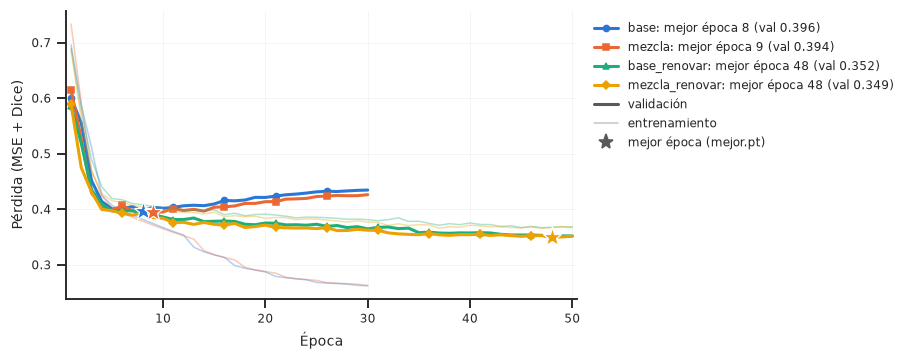

In [5]:
GUARDAR = False   # True: exporta a figuras/notebook/ (PNG 300 dpi + PDF)

fig, ax = plt.subplots(figsize=(6.0, 3.4))
leyenda = []
for nombre, _, color, marcador in REDES:
    log = LOGS[nombre]
    ep = log.epoca + 1                                  # epocas desde 1, como las imprime train.py
    ax.plot(ep, log.train_total, color=color, lw=1.0, alpha=0.35)
    ax.plot(ep, log.val_total, color=color, lw=2, marker=marcador, ms=4, markevery=5)
    i = int(log.val_total.idxmin())
    ax.plot(ep[i], log.val_total[i], marker="*", ms=13, color=color,
            markeredgecolor="white", markeredgewidth=0.8, zorder=5)
    leyenda.append(Line2D([], [], color=color, lw=2, marker=marcador, ms=4,
                          label=f"{nombre}: mejor época {ep[i]} (val {log.val_total[i]:.3f})"))
leyenda += [Line2D([], [], color="0.35", lw=2, label="validación"),
            Line2D([], [], color="0.35", lw=1.0, alpha=0.35, label="entrenamiento"),
            Line2D([], [], color="0.35", lw=0, marker="*", ms=10, label="mejor época (mejor.pt)")]
ax.set_xlabel("Época")
ax.set_ylabel("Pérdida (MSE + Dice)")
ax.set_xlim(0.5, max(len(l) for l in LOGS.values()) + 0.5)
ax.grid(alpha=0.25, lw=0.5)
ax.legend(handles=leyenda, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1.0))
guardar(fig, "curvas_entrenamiento", GUARDAR)
plt.show()

## 3. Diseño 2×2: datos de entrenamiento × renovación de muestras

Recall en `test_snr_mezcla` de las cuatro corridas del diseño. En el eje x está si las muestras de entrenamiento fueron fijas (20000) o nuevas en cada época; cada línea une las dos corridas con los mismos datos de entrenamiento (`base` o `mezcla`, que pone tenues junto a brillantes en la mitad de las imágenes). Si las líneas son paralelas, el efecto de renovar no depende de los datos; si no, hay interacción. Las barras son IC 95% de Wilson, que tratan a cada emisor como independiente. Las corridas con muestras renovadas también entrenaron más épocas (50 contra 30), así que ese factor incluye la diferencia de épocas.

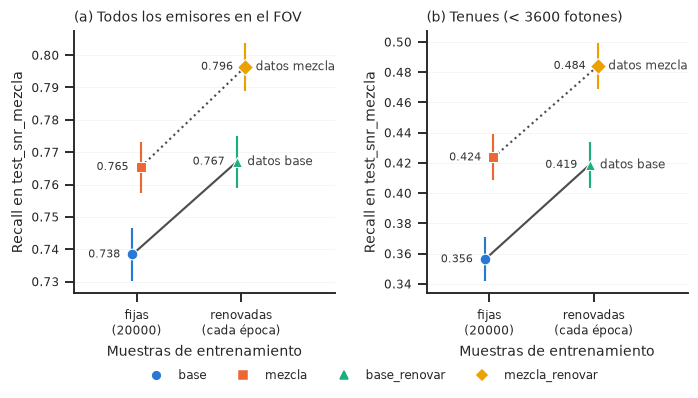

grupo                                                tenues  \
datos  train     corrida        epocas                        
base   fijas     base           30      0.356 (0.342-0.371)   
       renovadas base_renovar   50      0.419 (0.404-0.434)   
mezcla fijas     mezcla         30      0.424 (0.409-0.439)   
       renovadas mezcla_renovar 50      0.484 (0.469-0.500)   

grupo                                                 todos  
datos  train     corrida        epocas                       
base   fijas     base           30      0.738 (0.730-0.747)  
       renovadas base_renovar   50      0.767 (0.759-0.775)  
mezcla fijas     mezcla         30      0.765 (0.757-0.773)  
       renovadas mezcla_renovar 50      0.796 (0.789-0.804)

In [6]:
GUARDAR = False
conjunto = "test_snr_mezcla"
NIVELES_TRAIN = {"fijas": "fijas\n(20000)", "renovadas": "renovadas\n(cada época)"}
ESTILO_DATOS = {"base": "-", "mezcla": ":"}         # una linea por nivel de datos de entrenamiento

# comprobar el diseno contra el config.yaml de cada corrida
redes_2x2 = {r[0]: r for r in con_evaluacion(conjunto) if r[0] in DISENO_2X2}
for n in DISENO_2X2:
    if n not in redes_2x2:
        print(f"AVISO: {n} no esta disponible con evaluacion de {conjunto}; se omite del diseno")
for n in redes_2x2:
    d = CFGS[n]["datos"]
    real = ("mezcla" if d.get("prob_rango_completo", 0) > 0 else "base",
            "renovadas" if d.get("renovar_por_epoca", False) else "fijas")
    if real != DISENO_2X2[n]:
        print(f"AVISO: {n}: DISENO_2X2 dice {DISENO_2X2[n]} pero su config.yaml corresponde a {real}")

filas = []
for n, (datos, train) in DISENO_2X2.items():
    if n not in redes_2x2:
        continue
    g = EVAL[(n, conjunto)]["gt"].query("en_fov")
    for grupo, d in (("todos", g), ("tenues", g[g.photons < TENUE])):
        k, m = int(d.detectado.sum()), len(d)
        lo, hi = wilson(k, m)
        filas.append(dict(corrida=n, datos=datos, train=train, grupo=grupo, n=m, recall=k / m,
                          ic95_lo=lo, ic95_hi=hi, epocas=len(LOGS[n])))
t2x2 = pd.DataFrame(filas)

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.1), gridspec_kw=dict(wspace=0.35))
for ax, (grupo, titulo) in zip(axes, [("todos", "(a) Todos los emisores en el FOV"),
                                      ("tenues", f"(b) Tenues (< {TENUE:.0f} fotones)")]):
    d = t2x2[t2x2.grupo == grupo]
    for datos, ls in ESTILO_DATOS.items():
        dd = d[d.datos == datos].set_index("train").reindex(list(NIVELES_TRAIN)).dropna(subset=["recall"])
        x = np.array([list(NIVELES_TRAIN).index(t) for t in dd.index]) + (0.04 if datos == "mezcla" else -0.04)
        ax.plot(x, dd.recall, ls, color="0.3", lw=1.4, zorder=1)
        if len(dd):
            ax.text(x[-1] + 0.1, dd.recall.iloc[-1], f"datos {datos}", va="center", fontsize=8, color="0.25")
        for xi, (_, f) in zip(x, dd.iterrows()):
            _, _, color, marcador = redes_2x2[f.corrida]
            ax.errorbar(xi, f.recall, yerr=[[f.recall - f.ic95_lo], [f.ic95_hi - f.recall]], fmt=marcador,
                        color=color, ms=7, lw=1.4, capsize=0, markeredgecolor="white", markeredgewidth=0.7, zorder=3)
            ax.annotate(f"{f.recall:.3f}", (xi, f.recall), xytext=(-8, 0), textcoords="offset points",
                        ha="right", va="center", fontsize=7.5, color="0.2")
    ax.set_xticks(range(len(NIVELES_TRAIN)))
    ax.set_xticklabels(NIVELES_TRAIN.values())
    ax.set_xlim(-0.6, len(NIVELES_TRAIN) - 0.1)
    ax.set_xlabel("Muestras de entrenamiento")
    ax.set_ylabel(f"Recall en {conjunto}")
    ax.set_title(titulo, loc="left")
    ax.grid(alpha=0.25, lw=0.5, axis="y")
fig.legend(handles=leyenda_redes([redes_2x2[n] for n in DISENO_2X2 if n in redes_2x2], linestyle="none"),
           frameon=False, loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.08))
guardar(fig, "diseno_2x2", GUARDAR)
plt.show()

t2x2.assign(**{"recall (IC 95%)": [f"{r:.3f} ({lo:.3f}-{hi:.3f})" for r, lo, hi in
                                    zip(t2x2.recall, t2x2.ic95_lo, t2x2.ic95_hi)]}).pivot(
    index=["datos", "train", "corrida", "epocas"], columns="grupo", values="recall (IC 95%)")

## 4. Recall vs fotones y vs SNR

Recall de los emisores en el FOV por bin de fotones del emisor (a) y de SNR del píxel pico (b), con los mismos bins (logarítmicos) para todas las curvas. Línea continua y marcador lleno: `test_snr`, con brillo homogéneo dentro de cada imagen; línea discontinua y marcador hueco: `test_snr_mezcla`, con tenues junto a brillantes. Las bandas son IC 95% de Wilson; se omiten los bins con menos de 30 emisores.

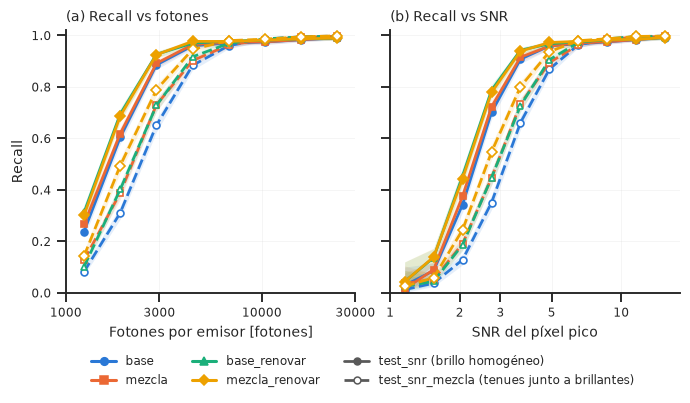

In [7]:
GUARDAR = False
gts_fov = {(r[0], cj): EVAL[(r[0], cj)]["gt"].query("en_fov") for cj, _, _ in CONJUNTOS for r in con_evaluacion(cj)}
bordes_fot = 1000.0 * 30.0 ** (np.arange(9) / 8)              # 8 bins en [1000, 30000], como figuras_localizacion.py
snr = pd.concat([g.snr for g in gts_fov.values()])
bordes_snr = np.geomspace(min(1.0, snr.min()), snr.max(), 11)  # 10 bins en el rango comun

fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.1), gridspec_kw=dict(wspace=0.12), sharey=True)
for ax, (columna, bordes, etiqueta, titulo, ticks) in zip(axes, [
        ("photons", bordes_fot, "Fotones por emisor", "(a) Recall vs fotones", [1000, 3000, 10000, 30000]),
        ("snr", bordes_snr, "SNR del píxel pico", "(b) Recall vs SNR", [1, 2, 3, 5, 10, 20])]):
    for r, _, color, marcador in REDES:
        for cj, ls, _ in CONJUNTOS:
            if (r, cj) not in gts_fov:
                continue
            t = recall_por_bin(gts_fov[(r, cj)], columna, bordes)
            ax.fill_between(t.centro, t.ic95_lo, t.ic95_hi, color=color, alpha=0.12, lw=0)
            ax.plot(t.centro, t.recall, ls, color=color, lw=1.8, marker=marcador, ms=4.5,
                    markerfacecolor=color if ls == "-" else "white", markeredgewidth=1.1)
    ax.set_xscale("log")
    ticks = [x for x in ticks if bordes[0] <= x <= bordes[-1]]
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.set_xticklabels([f"{x:g}" for x in ticks])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(bordes[0], bordes[-1])
    ax.set_xlabel(etiqueta + (" [fotones]" if columna == "photons" else ""))
    ax.set_title(titulo, loc="left")
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25, lw=0.5)
axes[0].set_ylabel("Recall")
leyenda = leyenda_redes(REDES) + [
    Line2D([], [], color="0.35", lw=1.8, ls=ls, marker="o", ms=4.5,
           markerfacecolor="0.35" if ls == "-" else "white", label=e) for _, ls, e in CONJUNTOS]
fig.legend(handles=leyenda, frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.04))
guardar(fig, "recall_fotones_snr", GUARDAR)
plt.show()

## 5. Precisión de localización vs fotones

RMSE lateral (a) y axial (b) de los emisores emparejados, por bin de fotones, para cada corrida sobre el conjunto elegido en `CONJUNTO`. Solo cuentan los emparejados (error lateral < 150 nm y axial < 300 nm), así que el RMSE no incluye los errores mayores que la tolerancia; se omiten los bins con menos de 30 emparejados.

**Cota de Cramér-Rao (línea punteada).** Se calcula con `simulador.crlb_3d` (información de Fisher de x, y, z, N y fondo, con ruido Poisson + lectura) para cada emisor del GT en el FOV del conjunto, con:
- sus propios fotones y su `z` del ground truth;
- el fondo medio de su imagen (`fondo_medio` de `muestras.csv`, en fotones/píxel). El fondo real de la mayoría de las imágenes no es uniforme, y el fondo local en el emisor puede ser mayor o menor;
- el ruido de lectura de su imagen (`read_noise` de `muestras.csv`) y la óptica del `config_simulador.json` del conjunto;
- el emisor centrado en un píxel y una ROI de 47×47 px (la cota cambia < 0.2% de 31 a 63 px; con 15 px, el valor por defecto, sale ~12% mayor porque recorta el halo de la PSF esférica).

La curva de cada bin es √(media de σ²ₓ + σ²ᵧ) (lateral) o √(media de σ²_z) (axial) sobre todos los emisores del bin (detectados o no), en nm. Es la cota de un estimador insesgado de un emisor aislado, con z desconocido. Con la PSF esférica y el emisor centrado en un píxel, la cota lateral es la misma que con z conocido (`simulador.crlb`).

**Sesgo de selección y cota.** En los bins con recall bajo (ver sección 4), el RMSE es solo de los emisores que la red detectó, que no son una muestra al azar del bin. Además, los errores mayores que la tolerancia no entran, y la red no es un estimador insesgado: aprendió que z está en [−800, 800] nm. Por eso el RMSE puede quedar por debajo de la cota, sobre todo a pocos fotones y en z. La tabla de abajo da el cociente RMSE / CRLB por bin para las corridas con muestras renovadas.

In [8]:
CONJUNTO = "test_snr"     # o "test_snr_mezcla"
TAM_ROI = 47


def crlb_nm(conjunto, gt):
    # CRLB [nm] de cada emisor del GT en el FOV con crlb_3d (x, y, z, N, b desconocidos): lateral
    # sqrt(sx^2 + sy^2) * pixel_nm y axial sz, con sus fotones, su z, el fondo medio y el ruido de
    # lectura de su imagen (muestras.csv) y la optica del conjunto
    cfg = sim.cargar_config(DATOS / conjunto / "config_simulador.json")
    banco = sim.BancoPSF(cfg)
    muestras = pd.read_csv(DATOS / conjunto / "muestras.csv").set_index("video_id")
    g = gt[gt.en_fov]
    fondo = muestras.fondo_medio.reindex(g.video_id).to_numpy()
    rn = muestras.read_noise.reindex(g.video_id).to_numpy()
    var_e2 = {v: sim._var_lectura_e2(replace(cfg, read_noise=float(v))) for v in np.unique(rn)}
    s = [sim.crlb_3d(banco, N, b, z_nm=z, tam_roi=TAM_ROI, var_lectura_e2=var_e2[v])
         for N, b, z, v in zip(g.photons, fondo, g.z_nm, rn)]
    return pd.DataFrame(dict(lat=[np.hypot(d["x"], d["y"]) * cfg.pixel_nm for d in s],
                             z=[d["z"] for d in s]), index=g.index)


CRLB = {}                 # conjunto -> CRLB por emisor (se calcula una vez, ~30 s por conjunto)
redes_c = con_evaluacion(CONJUNTO)
if redes_c and CONJUNTO not in CRLB:
    CRLB[CONJUNTO] = crlb_nm(CONJUNTO, EVAL[(redes_c[0][0], CONJUNTO)]["gt"])
print(f"CRLB (x, y, z) de {len(CRLB.get(CONJUNTO, []))} emisores de {CONJUNTO}")

CRLB (x, y, z) de 10943 emisores de test_snr


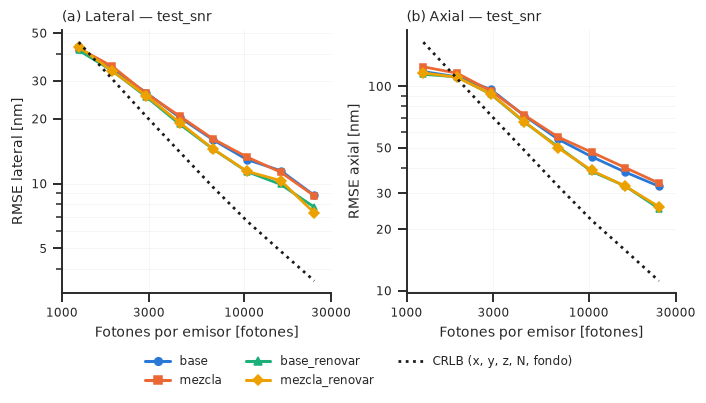

RMSE / CRLB por bin de fotones en test_snr (corridas con muestras renovadas):


In [9]:
GUARDAR = False


def rmse_por_bin(g, columna, bordes, n_min=30, log=True):
    # RMSE lateral y axial [nm] de los emparejados (en el FOV) por bin de g[columna]
    e = g[g.en_fov & g.detectado]
    b = pd.cut(e[columna], bordes, include_lowest=True)
    t = pd.DataFrame(dict(lat=e.dx_nm**2 + e.dy_nm**2, z=e.dz_nm**2)).groupby(b, observed=False).agg(["mean", "size"])
    tabla = pd.DataFrame(dict(centro=centros_bin(bordes, log), n=t[("lat", "size")].to_numpy(),
                              rmse_lat=np.sqrt(t[("lat", "mean")].to_numpy()), rmse_z=np.sqrt(t[("z", "mean")].to_numpy())))
    return tabla[tabla.n >= n_min].reset_index(drop=True)


def crlb_por_bin(conjunto, gt, bordes, n_min=30):
    # sqrt(media de CRLB^2) lateral y axial [nm] de todos los emisores del GT en el FOV por bin de fotones
    g = gt[gt.en_fov]
    c = (CRLB[conjunto] ** 2).groupby(pd.cut(g.photons, bordes, include_lowest=True), observed=False).agg(["mean", "size"])
    tabla = pd.DataFrame(dict(centro=centros_bin(bordes), n=c[("lat", "size")].to_numpy(),
                              crlb_lat=np.sqrt(c[("lat", "mean")].to_numpy()), crlb_z=np.sqrt(c[("z", "mean")].to_numpy())))
    return tabla[tabla.n >= n_min].reset_index(drop=True)


fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.1), gridspec_kw=dict(wspace=0.28))
rmse_bins = {}
for r, _, color, marcador in redes_c:
    rmse_bins[r] = rmse_por_bin(EVAL[(r, CONJUNTO)]["gt"], "photons", bordes_fot)
    for ax, col in zip(axes, ("rmse_lat", "rmse_z")):
        ax.plot(rmse_bins[r].centro, rmse_bins[r][col], "-", color=color, lw=1.8, marker=marcador, ms=4.5)
if CONJUNTO in CRLB:
    cota = crlb_por_bin(CONJUNTO, EVAL[(redes_c[0][0], CONJUNTO)]["gt"], bordes_fot)
    for ax, col in zip(axes, ("crlb_lat", "crlb_z")):
        ax.plot(cota.centro, cota[col], ":", color="0.1", lw=1.8)
for ax, titulo, etiqueta in zip(axes, ("(a) Lateral", "(b) Axial"), ("RMSE lateral [nm]", "RMSE axial [nm]")):
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.yaxis.set_major_locator(LogLocator(base=10, subs=(1, 2, 3, 5)))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.xaxis.set_major_locator(FixedLocator([1000, 3000, 10000, 30000]))
    ax.set_xticklabels(["1000", "3000", "10000", "30000"])
    ax.xaxis.set_minor_locator(NullLocator())
    ax.set_xlim(bordes_fot[0], bordes_fot[-1])
    ax.set_xlabel("Fotones por emisor [fotones]")
    ax.set_ylabel(etiqueta)
    ax.set_title(f"{titulo} — {CONJUNTO}", loc="left")
    ax.grid(alpha=0.25, lw=0.5, which="both")
leyenda = leyenda_redes(redes_c) + [Line2D([], [], color="0.1", lw=1.8, ls=":", label="CRLB (x, y, z, N, fondo)")]
fig.legend(handles=leyenda, frameon=False, loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.04))
guardar(fig, f"rmse_fotones_{CONJUNTO}", GUARDAR)
plt.show()

# cociente RMSE / CRLB por bin de fotones, para las corridas con muestras renovadas
renovar = [r for r in redes_c if CFGS[r[0]]["datos"].get("renovar_por_epoca", False)]
if CONJUNTO in CRLB and renovar:
    etiquetas_bin = {round(c, 6): f"{lo:.0f}–{hi:.0f}" for c, lo, hi in
                     zip(centros_bin(bordes_fot), bordes_fot[:-1], bordes_fot[1:])}
    cocientes = []
    for r, _, _, _ in renovar:
        t = rmse_bins[r].merge(cota, on="centro", suffixes=("", "_gt"))
        cocientes.append(pd.DataFrame({(r, "lateral"): (t.rmse_lat / t.crlb_lat).to_numpy(),
                                       (r, "axial"): (t.rmse_z / t.crlb_z).to_numpy()},
                                      index=[etiquetas_bin[round(c, 6)] for c in t.centro]))
    cocientes = pd.concat(cocientes, axis=1)
    cocientes.index.name = "fotones"
    print(f"RMSE / CRLB por bin de fotones en {CONJUNTO} (corridas con muestras renovadas):")
    display(cocientes.style.format("{:.2f}"))

## 6. Recall y RMSE vs z

Recall (a), RMSE lateral (b) y RMSE axial (c) por bin de 100 nm en z del emisor, sobre el conjunto elegido en `CONJUNTO`. La línea vertical marca z = 0; comparar cada curva a ambos lados de esa línea muestra la asimetría entre z negativo y positivo. La tabla de abajo resume cada corrida en las dos mitades (z < 0 y z > 0), con la diferencia (positiva menos negativa).

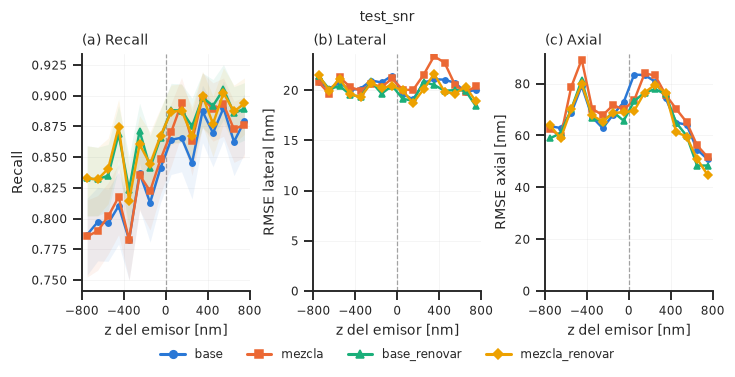

In [10]:
GUARDAR = False
CONJUNTO = "test_snr"
bordes_z = np.arange(-800, 801, 100)

redes_c = con_evaluacion(CONJUNTO)
fig, axes = plt.subplots(1, 3, figsize=(7.4, 2.8), gridspec_kw=dict(wspace=0.38))
for r, _, color, marcador in redes_c:
    g = EVAL[(r, CONJUNTO)]["gt"]
    t = recall_por_bin(g.query("en_fov"), "z_nm", bordes_z, log=False)
    axes[0].fill_between(t.centro, t.ic95_lo, t.ic95_hi, color=color, alpha=0.08, lw=0)
    axes[0].plot(t.centro, t.recall, "-", color=color, lw=1.6, marker=marcador, ms=3.5)
    e = rmse_por_bin(g, "z_nm", bordes_z, log=False)
    axes[1].plot(e.centro, e.rmse_lat, "-", color=color, lw=1.6, marker=marcador, ms=3.5)
    axes[2].plot(e.centro, e.rmse_z, "-", color=color, lw=1.6, marker=marcador, ms=3.5)
for ax, titulo, etiqueta in zip(axes, ("(a) Recall", "(b) Lateral", "(c) Axial"),
                                ("Recall", "RMSE lateral [nm]", "RMSE axial [nm]")):
    ax.axvline(0, color="0.6", lw=0.8, ls="--", zorder=0)
    ax.set_xlim(-800, 800)
    ax.set_xticks([-800, -400, 0, 400, 800])
    ax.set_xlabel("z del emisor [nm]")
    ax.set_ylabel(etiqueta)
    ax.set_title(titulo, loc="left")
    ax.grid(alpha=0.25, lw=0.5)
axes[1].set_ylim(bottom=0); axes[2].set_ylim(bottom=0)
fig.suptitle(CONJUNTO, x=0.5, y=1.02, fontsize=9)
fig.legend(handles=leyenda_redes(redes_c), frameon=False, loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.04))
guardar(fig, f"recall_rmse_z_{CONJUNTO}", GUARDAR)
plt.show()

filas = []
for r, _, _, _ in redes_c:
    g = EVAL[(r, CONJUNTO)]["gt"].query("en_fov")
    for mitad, d in (("z < 0", g[g.z_nm < 0]), ("z > 0", g[g.z_nm > 0])):
        e = d[d.detectado]
        filas.append({"corrida": r, "mitad": mitad, "recall": d.detectado.mean(),
                      "RMSE lateral [nm]": np.sqrt((e.dx_nm**2 + e.dy_nm**2).mean()),
                      "RMSE axial [nm]": np.sqrt((e.dz_nm**2).mean())})
mitades = pd.DataFrame(filas).pivot(index="corrida", columns="mitad").reindex([r[0] for r in redes_c])
for m in ("recall", "RMSE lateral [nm]", "RMSE axial [nm]"):
    mitades[(m, "diferencia")] = mitades[(m, "z > 0")] - mitades[(m, "z < 0")]
mitades = mitades[[(m, h) for m in ("recall", "RMSE lateral [nm]", "RMSE axial [nm]")
                   for h in ("z < 0", "z > 0", "diferencia")]]
mitades.style.format({c: ("{:+.3f}" if c[1] == "diferencia" else "{:.3f}") if c[0] == "recall" else
                      ("{:+.1f}" if c[1] == "diferencia" else "{:.1f}") for c in mitades.columns})

## 7. Recall de los tenues vs distancia al brillante más cercano

Para los emisores tenues (< 3600 fotones) de `test_snr_mezcla`, recall por bin de distancia al emisor brillante (> 10000 fotones) más cercano de su misma imagen; el último punto agrupa los tenues de imágenes sin ningún brillante. Es la gráfica de `fig_recall_vs_vecino` con todas las corridas. Las barras son IC 95% de Wilson y `n` es el número de tenues por bin (el mismo en todas las corridas).

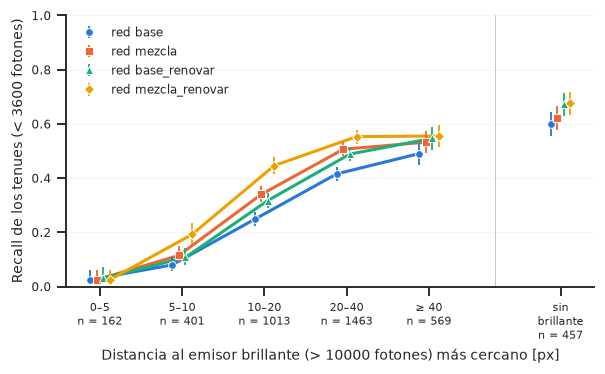

corrida,base,mezcla,base_renovar,mezcla_renovar,n
bin,,,,,
0–5,0.025 (0.010-0.062),0.025 (0.010-0.062),0.031 (0.013-0.070),0.025 (0.010-0.062),162
5–10,0.080 (0.057-0.110),0.115 (0.087-0.150),0.107 (0.081-0.141),0.192 (0.156-0.233),401
10–20,0.248 (0.222-0.275),0.340 (0.311-0.369),0.317 (0.289-0.346),0.446 (0.416-0.477),1013
20–40,0.416 (0.391-0.441),0.506 (0.481-0.532),0.489 (0.463-0.514),0.553 (0.527-0.578),1463
≥ 40,0.490 (0.449-0.531),0.533 (0.491-0.573),0.547 (0.505-0.587),0.555 (0.514-0.596),569
sin brillante,0.600 (0.554-0.643),0.621 (0.576-0.665),0.672 (0.627-0.713),0.678 (0.634-0.720),457


In [11]:
GUARDAR = False
conjunto = "test_snr_mezcla"
redes_c = con_evaluacion(conjunto)
gts_vec = {r[0]: distancia_al_brillante(EVAL[(r[0], conjunto)]["gt"]) for r in redes_c}
tabla_vec = tabla_recall_vs_vecino(gts_vec)

fig, ax = plt.subplots(figsize=(6.2, 3.2))
graficar_recall_vs_vecino(ax, tabla_vec, redes_c)
guardar(fig, "recall_vs_vecino", GUARDAR)
plt.show()

tabla_vec.assign(**{"recall (IC 95%)": [f"{r:.3f} ({lo:.3f}-{hi:.3f})" for r, lo, hi in
                                        zip(tabla_vec.recall, tabla_vec.ic95_lo, tabla_vec.ic95_hi)]}).pivot(
    index="bin", columns="corrida", values="recall (IC 95%)").reindex(tabla_vec.bin.unique())[
    [r[0] for r in redes_c]].assign(n=tabla_vec.groupby("bin").n.first())

## 8. Distribución de los errores de localización

Errores dx, dy y dz (detección menos ground truth) de los emisores emparejados en el FOV, uno por corrida, sobre el conjunto elegido en `CONJUNTO`. Cada violín es la densidad de los errores, con las líneas internas en los cuartiles; sobre cada uno está el RMSE de esa componente. Las colas están recortadas por la tolerancia del emparejamiento (150 nm lateral, 300 nm axial).

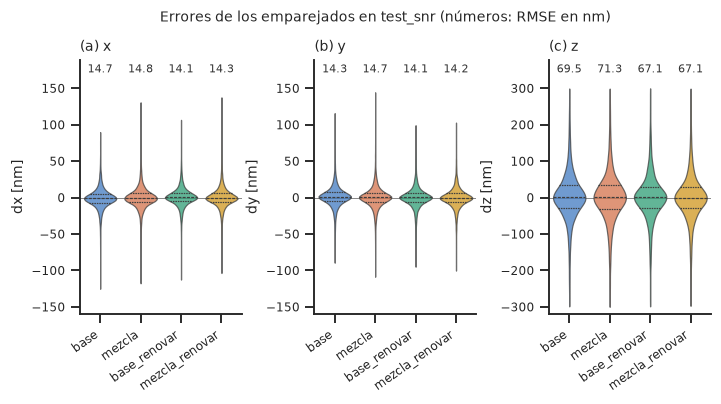

In [12]:
GUARDAR = False
CONJUNTO = "test_snr"

redes_c = con_evaluacion(CONJUNTO)
nombres_c = [r[0] for r in redes_c]
paleta = {n: c for n, _, c, _ in redes_c}
errores = pd.concat([EVAL[(r, CONJUNTO)]["gt"].query("en_fov and detectado")[["dx_nm", "dy_nm", "dz_nm"]]
                     .assign(corrida=r) for r in nombres_c], ignore_index=True)

fig, axes = plt.subplots(1, 3, figsize=(7.4, 3.0), gridspec_kw=dict(wspace=0.45))
for ax, (col, etiqueta), titulo in zip(axes, [("dx_nm", "dx [nm]"), ("dy_nm", "dy [nm]"), ("dz_nm", "dz [nm]")],
                                       ("(a) x", "(b) y", "(c) z")):
    sns.violinplot(data=errores, x="corrida", y=col, hue="corrida", order=nombres_c, hue_order=nombres_c,
                   palette=paleta, cut=0, inner="quart", linewidth=0.8, density_norm="width",
                   legend=False, ax=ax)
    for coleccion in ax.collections:
        coleccion.set_alpha(0.75)
    ax.axhline(0, color="0.5", lw=0.6, zorder=0)
    lim = 160 if col != "dz_nm" else 320
    ax.set_ylim(-lim, lim * 1.18)
    for i, n in enumerate(nombres_c):
        rmse = np.sqrt((errores.loc[errores.corrida == n, col] ** 2).mean())
        ax.text(i, lim * 1.05, f"{rmse:.1f}", ha="center", va="bottom", fontsize=7.5, color="0.2")
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("")
    ax.set_ylabel(etiqueta)
    ax.tick_params(axis="x", labelrotation=35)
    for t in ax.get_xticklabels():
        t.set_ha("right")
fig.suptitle(f"Errores de los emparejados en {CONJUNTO} (números: RMSE en nm)", y=1.03, fontsize=9)
guardar(fig, f"errores_{CONJUNTO}", GUARDAR)
plt.show()

## 9. Ejemplos de localización

Frames de `test_snr_mezcla` de cuatro categorías definidas solo con el ground truth: un tenue sin ningún brillante en la imagen, un tenue a ≥ 20 px del brillante más cercano, un tenue a < 10 px de un brillante y un frame denso (≥ 10 emisores en el FOV). En cada categoría los frames se sortean de forma uniforme con `SEMILLA_EJEMPLOS` entre los candidatos legibles (el tenue a ≥ 5 px del borde y ≤ 8 emisores en el frame, salvo los densos). No se condiciona en si la red detectó o no, ni se ordena por nada. Círculos: ground truth; cruces: detecciones de la corrida elegida; el color es z. Todos los paneles usan la misma escala de grises (raíz cuadrada, en e⁻), y el recuadro amarillo marca el tenue sorteado. Una cruz sobre un círculo de otro color es una detección con error axial mayor que la tolerancia (300 nm): cuenta como falso positivo y el emisor como perdido.

Tenue aislado: muestra 1700 (sorteada entre 186 frames); 2234 fotones, detectado; 5 detecciones
Tenue aislado: muestra 1354 (sorteada entre 186 frames); 1884 fotones, detectado; 4 detecciones
Tenue lejos: muestra 157 (sorteada entre 612 frames); 1014 fotones, a 35.1 px, perdido; 2 detecciones
Tenue lejos: muestra 85 (sorteada entre 612 frames); 3331 fotones, a 22.5 px, detectado; 2 detecciones
Tenue cerca: muestra 370 (sorteada entre 198 frames); 1907 fotones, a 2.5 px, perdido; 5 detecciones
Tenue cerca: muestra 1645 (sorteada entre 198 frames); 1236 fotones, a 9.5 px, perdido; 5 detecciones
Frame denso: muestra 1851 (sorteada entre 217 frames); 10 emisores, 8 detectados; 8 detecciones
Frame denso: muestra 1053 (sorteada entre 217 frames); 11 emisores, 8 detectados; 8 detecciones


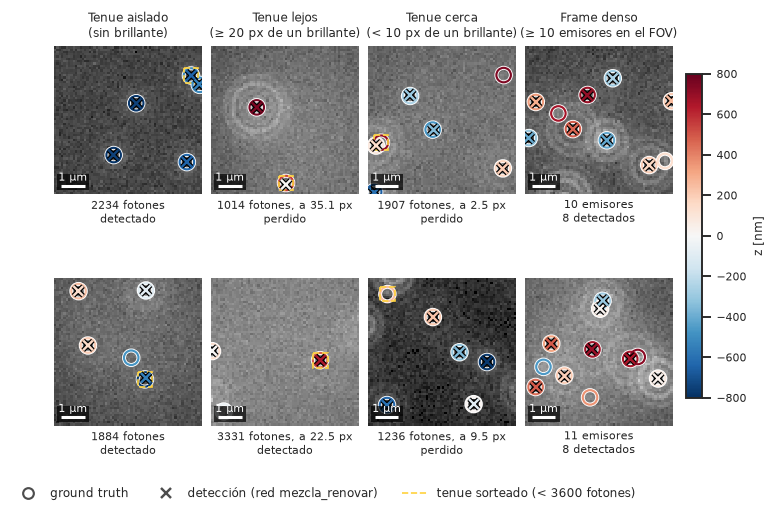

In [13]:
GUARDAR = False
N_POR_CATEGORIA = 2
conjunto = "test_snr_mezcla"

redes_c = con_evaluacion(conjunto)
r_ej = CORRIDA_EJEMPLOS or max(redes_c, key=lambda r: EVAL[(r[0], conjunto)]["resumen"]["metricas"]["jaccard"])[0]
imagenes, cfg_sim, px_um = conjunto_pregenerado(conjunto)
H, W = imagenes.shape[-2:]
g = distancia_al_brillante(EVAL[(r_ej, conjunto)]["gt"])
pred = EVAL[(r_ej, conjunto)]["pred"]

t = g[g.photons < TENUE]
legible = (t.x_px > 4) & (t.x_px < W - 5) & (t.y_px > 4) & (t.y_px < H - 5) & (t.n_frame <= 8)
aislado = np.isinf(t.dist_brillante)
frames_densos = g[g.n_frame >= 10].drop_duplicates(["video_id", "frame"])
CATEGORIAS = [("Tenue aislado", "sin brillante", t[aislado & legible]),
              ("Tenue lejos", "≥ 20 px de un brillante", t[~aislado & (t.dist_brillante >= 20) & legible]),
              ("Tenue cerca", "< 10 px de un brillante", t[(t.dist_brillante < 10) & legible]),
              ("Frame denso", "≥ 10 emisores en el FOV", frames_densos)]

# sorteo uniforme de frames (semilla fija) entre los candidatos de cada categoria, sin repetir frames;
# en las de tenues, si el frame tiene varios candidatos se sortea uno
rng = np.random.default_rng(SEMILLA_EJEMPLOS)
usados, casos = set(), []
for nombre, desc, cand in CATEGORIAS:
    frames = [f for f in cand[["video_id", "frame"]].drop_duplicates().itertuples(index=False, name=None)
              if f not in usados]
    for i in rng.choice(len(frames), size=min(N_POR_CATEGORIA, len(frames)), replace=False):
        v, fr = frames[i]
        en_frame = cand[(cand.video_id == v) & (cand.frame == fr)]
        casos.append((nombre, desc, v, fr, en_frame.iloc[rng.integers(len(en_frame))], len(frames)))
        usados.add((v, fr))

img_e = {(v, fr): imagen_electrones(imagenes, v, cfg_sim) for _, _, v, fr, _, _ in casos}
norma = norma_comun(list(img_e.values()))
ext = extension_um(H, W, px_um)
fig, axes = plt.subplots(N_POR_CATEGORIA, len(CATEGORIAS), figsize=(7.6, 2.15 * N_POR_CATEGORIA + 0.5),
                         gridspec_kw=dict(wspace=0.06, hspace=0.32), squeeze=False)
for ax in axes.ravel():
    ax.set_axis_off()
for j, (nombre, desc, _) in enumerate(CATEGORIAS):
    axes[0, j].set_title(f"{nombre}\n({desc})", fontsize=8)
    for i, (_, _, v, fr, f, n_cand) in enumerate([c for c in casos if c[0] == nombre]):
        ax = axes[i, j]
        ax.set_axis_on()
        gf = g[(g.video_id == v) & (g.frame == fr)]
        pf = pred[(pred.video_id == v) & (pred.frame == fr)]
        dibujar_frame(ax, img_e[(v, fr)], gf, pf, px_um, norma)
        barra_escala(ax, ext)
        if nombre == "Frame denso":
            texto = f"{len(gf)} emisores\n{int(gf.detectado.sum())} detectados"
        else:
            marcar_emisor(ax, f.x_px, f.y_px, px_um)
            dist = "" if np.isinf(f.dist_brillante) else f", a {f.dist_brillante:.1f} px"
            texto = f"{f.photons:.0f} fotones{dist}\n{'detectado' if f.detectado else 'perdido'}"
        ax.set_xlabel(texto, fontsize=7, labelpad=3)
        print(f"{nombre}: muestra {v} (sorteada entre {n_cand} frames); {texto.replace(chr(10), ', ')}; "
              f"{len(pf)} detecciones")
barra_z(fig, axes)
leyenda = [Line2D([], [], lw=0, marker="o", ms=7, markerfacecolor="none", markeredgecolor="0.3",
                  markeredgewidth=1.4, label="ground truth"),
           Line2D([], [], lw=0, marker="x", ms=6, color="0.3", markeredgewidth=1.6, label=f"detección (red {r_ej})"),
           Line2D([], [], lw=1.1, ls="--", color=COLOR_TENUE, label=f"tenue sorteado (< {TENUE:.0f} fotones)")]
fig.legend(handles=leyenda, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.45, 0.04))
guardar(fig, "ejemplos_localizacion", GUARDAR)
plt.show()

Recall de cada categoría (todos sus emisores candidatos, no solo los sorteados) para todas las corridas, como referencia de qué tan típicos son los ejemplos de arriba.

In [14]:
filas = []
for r, _, _, _ in redes_c:
    gr = distancia_al_brillante(EVAL[(r, conjunto)]["gt"])
    tr = gr[gr.photons < TENUE]
    cats = {"Tenue aislado": tr[np.isinf(tr.dist_brillante)],
            "Tenue lejos": tr[~np.isinf(tr.dist_brillante) & (tr.dist_brillante >= 20)],
            "Tenue cerca": tr[tr.dist_brillante < 10],
            "Frame denso": gr[gr.n_frame >= 10]}
    for nombre, d in cats.items():
        filas.append(dict(categoria=nombre, corrida=r, n=len(d), recall=d.detectado.mean()))
pd.DataFrame(filas).pivot(index="categoria", columns="corrida", values="recall").reindex(
    [c[0] for c in CATEGORIAS])[[r[0] for r in redes_c]].assign(
    n=pd.DataFrame(filas).groupby("categoria").n.first()).style.format(
    {r[0]: "{:.3f}" for r in redes_c})

corrida,base,mezcla,base_renovar,mezcla_renovar,n
categoria,,,,,
Tenue aislado,0.600,0.621,0.672,0.678,457
Tenue lejos,0.437,0.514,0.505,0.554,2032
Tenue cerca,0.064,0.089,0.085,0.144,563
Frame denso,0.675,0.713,0.712,0.751,2290
